# Ajuste con regresion de calibracion de un termometro

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [59]:
df = pd.read_csv("data/temp.csv")
df

,INDICACION DEL TERMOMETRO (C),TEMPERATURA CONVENCIONALMENTE VERDADERA (C),CORRECCIÓN (C),INCERTIDUMBRE (C)
0,18.18,18.017,-0.163,0.017
1,19.19,19.008,-0.183,0.017
2,20.19,20.018,-0.172,0.018
3,21.18,21.006,-0.174,0.018
4,22.20,22.013,-0.187,0.018


In [111]:
df.dtypes

INDICACION DEL TERMOMETRO (C)                  float64
TEMPERATURA CONVENCIONALMENTE VERDADERA (C)    float64
CORRECCIÓN (C)                                 float64
INCERTIDUMBRE (C)                              float64
dtype: object

In [81]:
X = df.iloc[:, 0]
y = df.iloc[:, 1]

In [ ]:
X.values.reshape(-1, 1)

0    18.18
1    19.19
2    20.19
3    21.18
4    22.20
Name: INDICACION DEL TERMOMETRO (C), dtype: float64

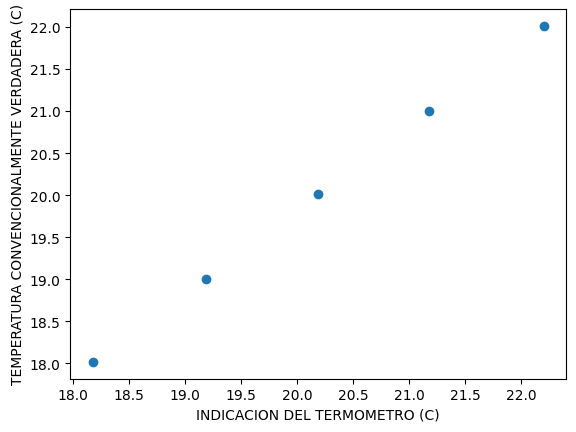

In [54]:
plt.scatter(X, y)
plt.xlabel("INDICACION DEL TERMOMETRO (C)")
plt.ylabel("TEMPERATURA CONVENCIONALMENTE VERDADERA (C)")
plt.show()

## 1.1 Ajuste mediante Regresion Lineal

In [95]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X.values.reshape(-1, 1), y)

print(model.coef_)
print(model.intercept_)
a = model.coef_[0]
b = model.intercept_

eq = f"y = {a:.4f}x {b:.4f}"


[0.99599852]
-0.094818140250581


In [86]:
X_pred = model.predict(X.values.reshape(-1, 1))

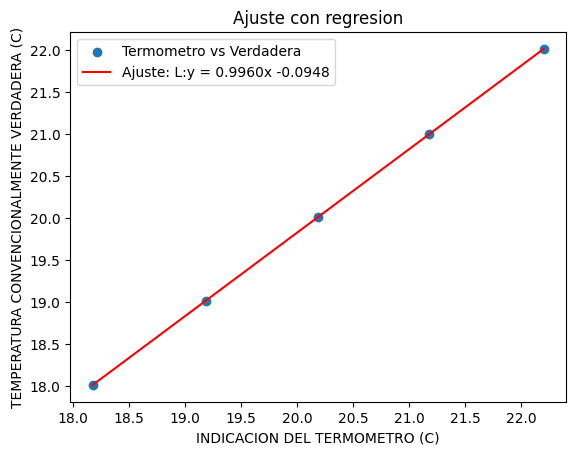

In [101]:
plt.scatter(X, y)
plt.plot(X, X_pred, color="red")
plt.xlabel("INDICACION DEL TERMOMETRO (C)")
plt.ylabel("TEMPERATURA CONVENCIONALMENTE VERDADERA (C)")
plt.title(f"Ajuste con regresion")
plt.legend(["Termometro vs Verdadera", "Ajuste: L:" + eq])
plt.show()

### 1.1.1 Temperatura convensionalmente verdader y ajustada en (C)

In [115]:
df_ajusted = pd.DataFrame({
    "INDICACION DEL TERMOMETRO EN (C)": X,
    "TEMPERATURA CONVENCIONALMENTE VERDADERA (C)": y,
    "TEMPERATURA CONVENCIONALMENTE VERDADERA (AJUSTADA) EN (C)": map(lambda x: round(x, 3), X_pred)
})
df_ajusted

,INDICACION DEL TERMOMETRO EN (C),TEMPERATURA CONVENCIONALMENTE VERDADERA (C),TEMPERATURA CONVENCIONALMENTE VERDADERA (AJUSTADA) EN (C)
0,18.18,18.017,18.012
1,19.19,19.008,19.018
2,20.19,20.018,20.014
3,21.18,21.006,21.000
4,22.20,22.013,22.016


### 1.1.2  Correccion Real vs Predicha

In [114]:
df_ajusted_diff = pd.DataFrame({
    "INDICACION DEL TERMOMETRO EN (C)": X,
    "CORRECCION DADA EN (C)": df.iloc[:, 2],
    "CORRECCION SEGUN AJUSTE  EN (C)": map(lambda x, y: round(x - y, 4), X_pred, y)
})

df_ajusted_diff

,INDICACION DEL TERMOMETRO EN (C),CORRECCION DADA EN (C),CORRECCION SEGUN AJUSTE EN (C)
0,18.18,-0.163,-0.0046
1,19.19,-0.183,0.0104
2,20.19,-0.172,-0.0036
3,21.18,-0.174,-0.0056
4,22.20,-0.187,0.0033


### 1.2.3 EVALUACION DE AJUSTE

In [116]:
# Evaluacion del ajuste

from sklearn.metrics import r2_score

r2 = r2_score(y, X_pred)
print(f"R2 = {r2:.4f}")

R2 = 1.0000


Esto significa que el modelo de regresion de calibracion de un termometro es un buen ajuste.